 # 4D-OBC aggregate
 
This notebook explains how to use the aggregate-function of the py4dgeo-packag which automatically merges similar 4D-OBCs to one.  

Implemented in: `py4dgeo.aggregate4dobcs`

**Author(s)** 

Scharnagl, Robin (Technische Universität München)

**Related publication**

 Ulm M, Elias M,  Eltner A, Lotsari E & Anders K. (2025). Automated change detection in photogrammetric 4D point clouds – transferability and extension of 4D objects‑by‑change 
for monitoring riverbank dynamics using low‑cost cameras. *Applied Geomatics*, https://doi.org/10.1007/s12518-025-00623-9   


## **Method description**
This section should provide a detailed technical explanation of the method:

- **Theoretical foundation**: Due to uncorrelated noise, the extraction of 4D-OBCs tends to oversegment, which leads to multiple 4D-OBCs describing one process. This function merges 4D-OBCs that overlap in time and space, to create just one object.

- **Algorithm**: The algorithm first checks the change direction of each object. It then calculates the spatial and temporal overlap of the OBCs. If the OBC's changes point in the same direction, and their temporal and spatial overlap exceeds a user-defined threshold, their link is stored. In the last step, these get fused to one single 4D-OBC

- **Key parameters**: The parameters that the user can define are the following:
    - `time_threshold` (float, 0 - 1): threshold for temporal overlap, 1: complete overlap, 0: no overlap
    - `spatial_threshold`(float, 0 - 1): thershold for spatial overlap, 1: complete overlap, 0: no overlap


First, we download the dataset:

In [ ]:
# Load Required Package
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import pooch
import os
from datetime import datetime
import sys
import py4dgeo

C:\Users\schar\OneDrive\Desktop\WorkingStudent\RSA\Tasks\py4dgeo\src\py4dgeo\segmentation.py


In [2]:

# Load Dataset
# Download data from zenodo and set path to point cloud folder
p = pooch.Pooch(base_url="doi:10.5281/zenodo.10003574/", path=pooch.os_cache("py4dgeo"))
p.load_registry_from_doi()
p.fetch("module3.zip", processor=pooch.Unzip(), progressbar=True)
pc_dir = p.path / "module3.zip.unzip" / "module3" / "schneeferner" / "pointclouds"


def parse_timestamp(fname):
    ts_str = "_".join(fname.split(".")[0].split("_")[1:])  # YYMMDD_hhmmss
    return datetime.strptime(ts_str, "%y%m%d_%H%M%S")


pc_files = sorted(
    (f for f in os.listdir(pc_dir) if f.endswith(".laz")),
    key=parse_timestamp,
)
timestamps = [parse_timestamp(f) for f in pc_files]

We then create a SpatiotemporalAnalysis-object from the given dataset compute the M3C2-distances and add the epochs to the analysis object

In [15]:
analysis = py4dgeo.SpatiotemporalAnalysis(str(pc_dir / "schneeferner.zip"), force=True)
# read the reference epoch and set the timestamp
reference_epoch = py4dgeo.read_from_las(str(pc_dir / pc_files[0]))
reference_epoch.timestamp = timestamps[0]

# set the reference epoch in the spatiotemporal analysis object and use the points as the corepoints
analysis.reference_epoch = reference_epoch
analysis.corepoints = reference_epoch.cloud # add some downsampling for speed [::20]

analysis.m3c2 = py4dgeo.M3C2(cyl_radius=2.0, normal_radii=[2.0])
epochs_to_add = []
for fname, ts in zip(pc_files[1:], timestamps[1:]):
    epoch = py4dgeo.read_from_las(str(pc_dir / fname))
    epoch.timestamp = ts
    epochs_to_add.append(epoch)

analysis.add_epochs(*epochs_to_add)

[2026-10-26 15:29:14][INFO] Creating analysis file C:\Users\schar\AppData\Local\py4dgeo\py4dgeo\Cache\module3.zip.unzip\module3\schneeferner\pointclouds\schneeferner.zip
[2026-10-26 15:29:14][INFO] Reading point cloud from file 'C:\Users\schar\AppData\Local\py4dgeo\py4dgeo\Cache\module3.zip.unzip\module3\schneeferner\pointclouds\schneeferner_180418_120027.laz'
[2026-10-26 15:29:14][INFO] Building KDTree structure with leaf parameter 10
[2026-10-26 15:29:14][INFO] Saving epoch to file 'C:\Users\schar\AppData\Local\Temp\tmpa470vp10\reference_epoch.zip'
[2026-10-26 15:29:15][INFO] Saving a file without normals.
[2026-10-26 15:29:15][INFO] Initializing Epoch object from given point cloud
[2026-10-26 15:29:15][INFO] Building KDTree structure with leaf parameter 10
[2026-10-26 15:29:15][INFO] Saving epoch to file 'C:\Users\schar\AppData\Local\Temp\tmp_eqdtggp\corepoints.zip'
[2026-10-26 15:29:15][INFO] Saving a file without normals.
[2026-10-26 15:29:15][INFO] Reading point cloud from file '

The next step is setting up the RegionGrowingAlgorithm. We can speecify which method we want to use. There are three methods available:'linear_rdp' (Ramer Douglas Peucker), 'linear_dtr' (Decision Tree Regression) and 'volume_cpd' (to assure backward compatibility, this mehtod is the default, when no method is given). This creates the objects to be aggregated

In [16]:
algo = py4dgeo.RegionGrowingAlgorithm(
    neighborhood_radius=2.0,
    seed_subsampling=50,
    height_threshold=0.5,
    minperiod=48,
    method="linear_rdp",  # 'linear_rdp', 'linear_dtr' or 'volume_cpd'
)

objects = algo.run(analysis)

[2026-10-26 15:30:20][INFO] Starting: Find seed candidates in time series
[2026-10-26 15:30:22][INFO] Iterating over seedpoints (RDP)
[2026-10-26 15:31:33][INFO] Finished in 73.2178s: Find seed candidates in time series
[2026-10-26 15:31:33][INFO] Starting: Sort seed candidates by priority
[2026-10-26 15:31:34][INFO] Finished in 0.9306s: Sort seed candidates by priority
[2026-10-26 15:31:35][INFO] Starting: Performing region growing on seed candidate 1/3734
[2026-10-26 15:31:35][INFO] Finished in 0.0878s: Performing region growing on seed candidate 1/3734
[2026-10-26 15:31:35][INFO] Starting: Performing region growing on seed candidate 2/3734
[2026-10-26 15:31:35][INFO] Finished in 0.4422s: Performing region growing on seed candidate 2/3734
[2026-10-26 15:31:35][INFO] Starting: Performing region growing on seed candidate 130/3734
[2026-10-26 15:31:36][INFO] Finished in 0.5245s: Performing region growing on seed candidate 130/3734
[2026-10-26 15:31:36][INFO] Starting: Performing region 

With the SpatiotemporalAnalysis-object, we can simply add the merge-function and define the parameters to the users-preference. 

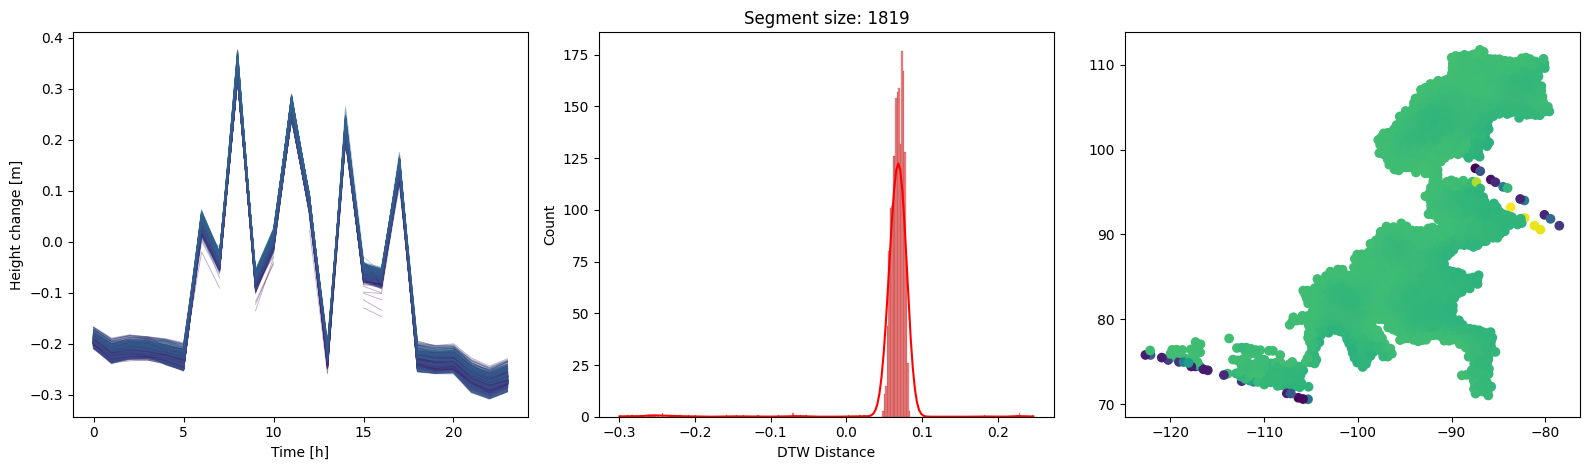

In [20]:
# Run the Method
merged = analysis.aggregate_4dobcs(time_threshold=0.1, spatial_threshold=0.3)

# Plot a merged object of change
merged[5].plot()

## References
-  Ulm M, Elias M,  Eltner A, Lotsari E & Anders K. (2025). Automated change detection in photogrammetric 4D point clouds – transferability and extension of 4D objects‑by‑change 
for monitoring riverbank dynamics using low‑cost cameras. *Applied Geomatics*, pages. https://doi.org/10.1007/s12518-025-00623-9   